# Leveling analysis
Recomputes the leveling error and loop rate from the raw CSV logs.
Each log = 10+ s of closed-loop leveling with the base tilted to 0, 10, 20 or 30 degrees (phone level app).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TILTS = [0, 10, 20, 30]   # base tilt for each run, in degrees
SETTLE_S = 5              # ignore the first 5 s while the servo settles

In [3]:
# Load one file first and look at it, so we know the column names are right
df = pd.read_csv("../logs/level_tilt0.csv")
print(df.columns.tolist())
df.head()

['t_ms', 'accel_deg', 'filt_deg', 'servo_cmd']


,t_ms,accel_deg,filt_deg,servo_cmd
0,1934,2.79,2.51,90.0
1,1939,2.81,2.50,89.9
2,1944,2.56,2.50,89.9
3,1949,2.50,2.49,89.8
4,1954,2.98,2.49,89.8


In [4]:
runs = {}      # tilt -> DataFrame, kept for plotting
results = []   # one row of numbers per run

for tilt in TILTS:
    df = pd.read_csv(f"../logs/level_tilt{tilt}.csv")

    # time in seconds, starting at 0
    df["t_s"] = (df["t_ms"] - df["t_ms"].iloc[0]) / 1000.0

    # keep only the settled part
    df = df[df["t_s"] >= SETTLE_S]

    angle = df["filt_deg"].to_numpy()   # platform tilt from the filter
    dt_ms = np.diff(df["t_ms"].to_numpy())  # time between samples

    results.append({
        "base_tilt_deg": tilt,
        "worst_error_deg": np.max(np.abs(angle)),  # the resume number
        "mean_deg": np.mean(angle),                # offset: is it sitting off-level?
        "std_deg": np.std(angle),                  # wobble / hunting around level
        "loop_hz": 1000.0 / np.mean(dt_ms),        # samples per second
    })
    runs[tilt] = df

summary = pd.DataFrame(results).round(2)
summary

,base_tilt_deg,worst_error_deg,mean_deg,std_deg,loop_hz
0,0,0.18,-0.15,0.01,199.92
1,10,2.62,0.12,0.81,199.92
2,20,0.18,-0.14,0.02,199.92
3,30,0.46,0.43,0.01,199.92


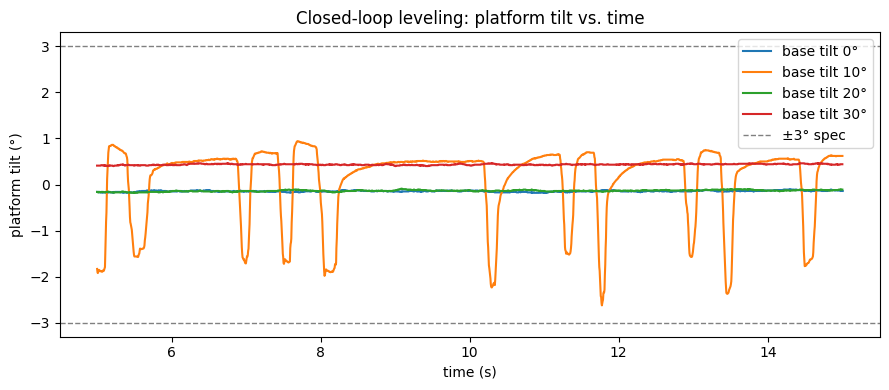

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
for tilt, df in runs.items():
    ax.plot(df["t_s"], df["filt_deg"], label=f"base tilt {tilt}°")

ax.axhline(3, color="gray", linestyle="--", linewidth=1)
ax.axhline(-3, color="gray", linestyle="--", linewidth=1, label="±3° spec")
ax.set_xlabel("time (s)")
ax.set_ylabel("platform tilt (°)")
ax.set_title("Closed-loop leveling: platform tilt vs. time")
ax.legend()
fig.tight_layout()
fig.savefig("../plots/leveling.png", dpi=150)
plt.show()

## Result
Fill in from the summary table above (real numbers only):
- Worst leveling error: ±2.6° at up to 30° base tilt (spec: ±3°)
- Loop rate with servo running: 200 Hz (spec: ≥100 Hz)